In [2]:
import xml.etree.ElementTree as ET
import cv2
import matplotlib.pyplot as plt


Read our xml data

In [3]:
xml_path="../data/train/00001.xml"
tree = ET.parse(xml_path)
root=tree.getroot()

filename = root.find("filename").text
print("Image:", filename)

for obj in root.findall("object"):

    character = obj.find("name").text

    box = obj.find("bndbox")

    xmin = int(box.find("xmin").text)
    ymin = int(box.find("ymin").text)
    xmax = int(box.find("xmax").text)
    ymax = int(box.find("ymax").text)

    print(character, xmin, ymin, xmax, ymax)

Image: for_xml_2811.jpg
1 59 56 101 171
2 96 63 149 181
ز 157 97 211 199
8 219 113 273 216
1 285 124 325 245
6 318 141 382 242
1 396 177 435 282
1 442 192 488 295


load our image

In [4]:
image = cv2.imread("../data/train/00001.jpg")

In [5]:
characters = []

for obj in root.findall("object"):

    label = obj.find("name").text

    box = obj.find("bndbox")

    xmin = int(box.find("xmin").text)
    ymin = int(box.find("ymin").text)
    xmax = int(box.find("xmax").text)
    ymax = int(box.find("ymax").text)

    cropped_character = image[ymin:ymax, xmin:xmax]
    characters.append((label, cropped_character))

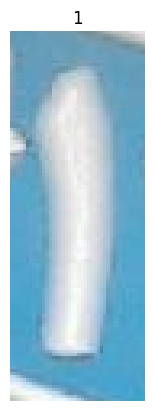

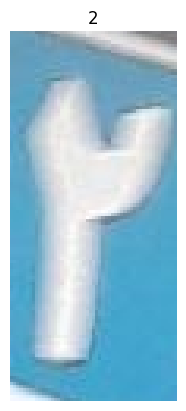

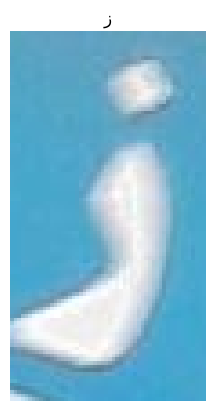

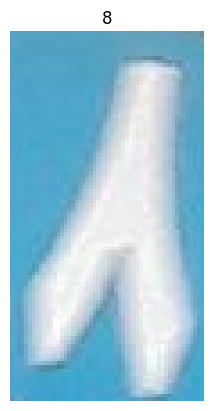

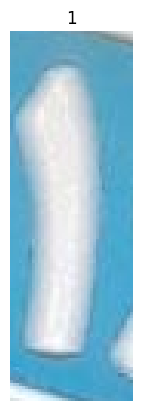

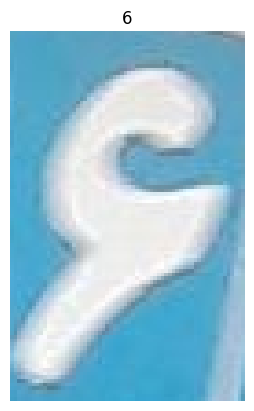

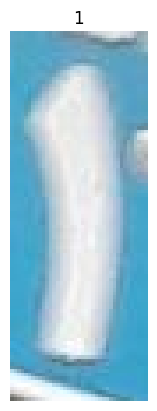

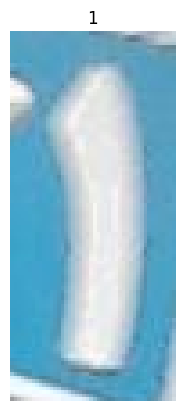

In [6]:
for label, char_image in characters:

    char_rgb = cv2.cvtColor(char_image, cv2.COLOR_BGR2RGB)

    plt.imshow(char_rgb)
    plt.title(label)
    plt.axis("off")
    plt.show()

In [7]:
target_width = 32
target_height = 64

resized_characters = []

for label, char_image in characters:
    resized_image = cv2.resize(
        char_image,
        (target_width, target_height)
    )
    resized_characters.append((label, resized_image))

In [8]:
grayscale_characters = []

for label , char_image in resized_characters:
    gray_image=cv2.cvtColor(char_image,cv2.COLOR_BGR2GRAY)
    grayscale_characters.append((label, gray_image))

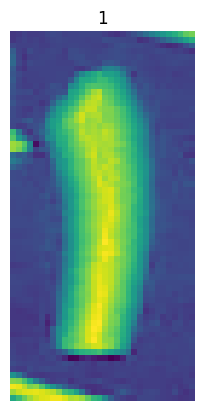

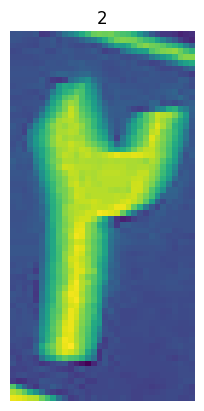

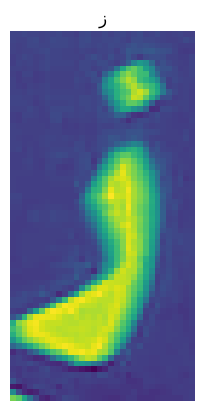

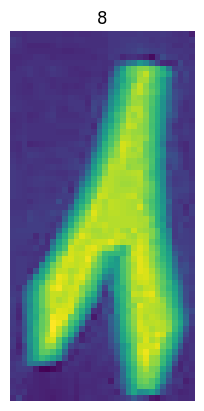

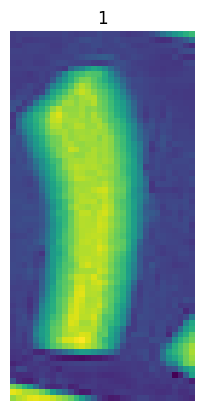

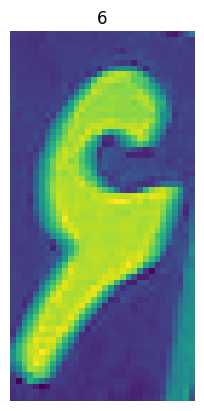

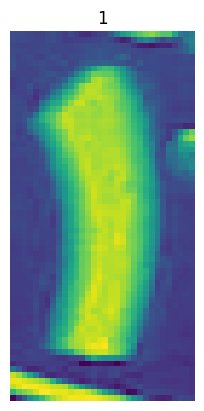

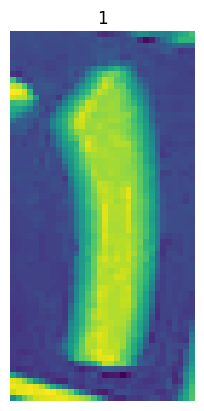

In [9]:
for label , char_image in grayscale_characters:
    plt.imshow(char_image)
    plt.title(label)
    plt.axis("off")
    plt.show()

Normalization

In [10]:
normalized_characters = []

for label, gray_image in grayscale_characters:
    normalized_image = gray_image.astype("float32") / 255.0
    normalized_characters.append((label, normalized_image))

label, image = normalized_characters[0]

